### IPL 2022 Capstone Project

**The Indian Premier League (IPL) is a professional T20 cricket league in India, featuring franchises representing cities. This project explores IPL 2022 match-level data to derive meaningful insights and understand match outcomes, player performances, and team dynamics.**

**These are some of the important columns that we'll focus on for meaningful insights in this project.**

**column names: Variable Type**
* date : string  
* venue : string  
* stage : string  
* team1 : string  
* team2 : string  
* toss_winner : string  
* toss_decision : string  
* first_ings_score : integer  
* second_ings_score : integer  
* match_winner : string  
* won_by : string  
* margin : integer  
* player_of_the_match : string  
* top_scorer : string  
* highscore : integer  
* best_bowling : string  
* best_bowling_fgure : string  
* gure : string  


### Loading the Libraries and Dataset

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [4]:
ipl_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Data Visualization/IPL.csv")
ipl_df.head()

,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,second_ings_score,second_ings_wkts,match_winner,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure
0,1,"March 26,2022","Wankhede Stadium, Mumbai",Chennai,Kolkata,Group,Kolkata,Field,131,5,133,4,Kolkata,Wickets,6,Umesh Yadav,MS Dhoni,50,Dwayne Bravo,3--20
1,2,"March 27,2022","Brabourne Stadium, Mumbai",Delhi,Mumbai,Group,Delhi,Field,177,5,179,6,Delhi,Wickets,4,Kuldeep Yadav,Ishan Kishan,81,Kuldeep Yadav,3--18
2,3,"March 27,2022","Dr DY Patil Sports Academy, Mumbai",Banglore,Punjab,Group,Punjab,Field,205,2,208,5,Punjab,Wickets,5,Odean Smith,Faf du Plessis,88,Mohammed Siraj,2--59
3,4,"March 28,2022","Wankhede Stadium, Mumbai",Gujarat,Lucknow,Group,Gujarat,Field,158,6,161,5,Gujarat,Wickets,5,Mohammed Shami,Deepak Hooda,55,Mohammed Shami,3--25
4,5,"March 29,2022","Maharashtra Cricket Association Stadium,Pune",Hyderabad,Rajasthan,Group,Hyderabad,Field,210,6,149,7,Rajasthan,Runs,61,Sanju Samson,Aiden Markram,57,Yuzvendra Chahal,3--22


In [5]:
ipl_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74 entries, 0 to 73
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   match_id             74 non-null     int64 
 1   date                 74 non-null     object
 2   venue                74 non-null     object
 3   team1                74 non-null     object
 4   team2                74 non-null     object
 5   stage                74 non-null     object
 6   toss_winner          74 non-null     object
 7   toss_decision        74 non-null     object
 8   first_ings_score     74 non-null     int64 
 9   first_ings_wkts      74 non-null     int64 
 10  second_ings_score    74 non-null     int64 
 11  second_ings_wkts     74 non-null     int64 
 12  match_winner         74 non-null     object
 13  won_by               74 non-null     object
 14  margin               74 non-null     int64 
 15  player_of_the_match  74 non-null     object
 16  top_scorer

Check the size of rows and columns of the dataset

In [6]:
print(f"Total rows are: {ipl_df.shape[0]}\nTotal columns are: {ipl_df.shape[1]}")

Total rows are: 74
Total columns are: 20


In [7]:
print(f"NULL values in each rows: {ipl_df.isnull().sum()}")
print(f"\nTotal NULL values: {ipl_df.isnull().sum().sum()}")

NULL values in each rows: match_id               0
date                   0
venue                  0
team1                  0
team2                  0
stage                  0
toss_winner            0
toss_decision          0
first_ings_score       0
first_ings_wkts        0
second_ings_score      0
second_ings_wkts       0
match_winner           0
won_by                 0
margin                 0
player_of_the_match    0
top_scorer             0
highscore              0
best_bowling           0
best_bowling_figure    0
dtype: int64

Total NULL values: 0


**Now, Basic Questions**

1. Which team won the most matches?

In [8]:
match_winner = ipl_df['match_winner'].value_counts()
print(type(match_winner))
print(match_winner)

<class 'pandas.core.series.Series'>
match_winner
Gujarat      12
Rajasthan    10
Banglore      9
Lucknow       9
Punjab        7
Delhi         7
Kolkata       6
Hyderabad     6
Chennai       4
Mumbai        4
Name: count, dtype: int64


<Axes: ylabel='match_winner'>

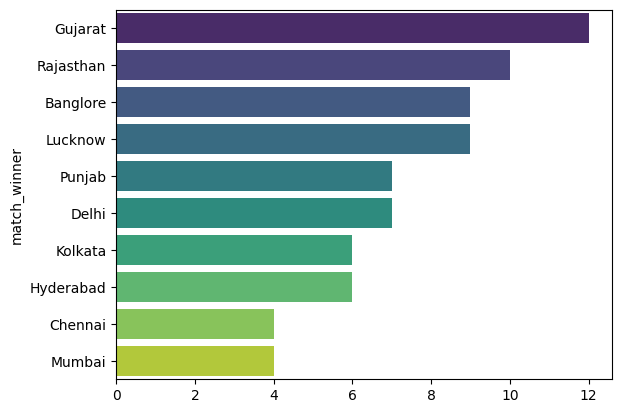

In [9]:
sns.barplot(y=match_winner.index, x=match_winner.values, palette='viridis')
#sns.barplot(match_winner)

2. Toss Decision Trends

<Axes: xlabel='toss_decision', ylabel='count'>

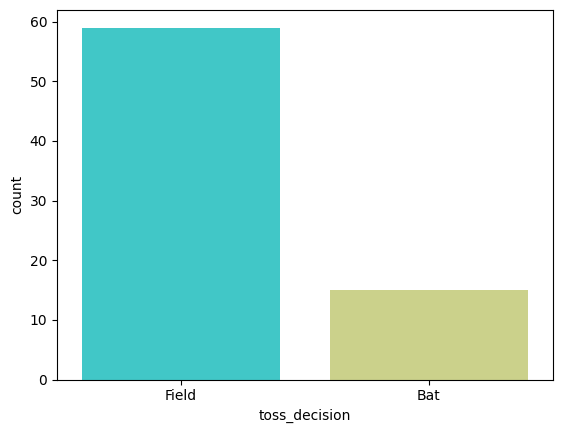

In [10]:
sns.countplot(x=ipl_df['toss_decision'], palette='rainbow')

3. Toss Winner vs Match Winner

In [11]:
toss_vs_match = (ipl_df['toss_winner'] == ipl_df['match_winner']).value_counts()
print(toss_vs_match)
print(ipl_df.shape[0])
toss_pct = (toss_vs_match / toss_vs_match.sum()) * 100
print(toss_pct.round(2))

False    38
True     36
Name: count, dtype: int64
74
False    51.35
True     48.65
Name: count, dtype: float64


<Axes: xlabel='None'>

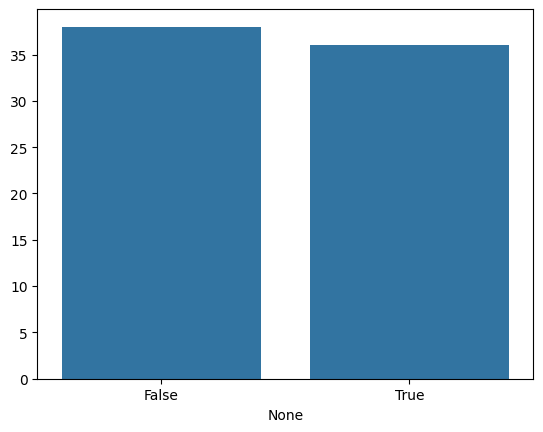

In [12]:
sns.barplot(x = toss_vs_match.index, y=toss_vs_match.values)

In [13]:
ipl_df['won_by'].value_counts()

,count
won_by,
Wickets,37
Runs,37


<Axes: xlabel='won_by', ylabel='count'>

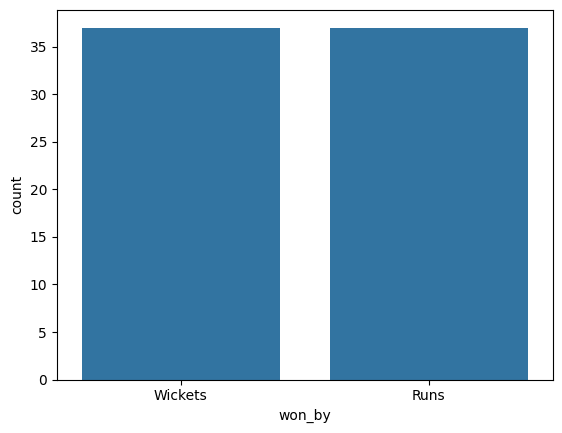

In [14]:
sns.barplot(ipl_df['won_by'].value_counts())

###  Key Player Performances

1 Most "Player of the Match" Awards

In [15]:
pom = ipl_df['player_of_the_match'].value_counts()
pom = pom.head(7)

<Axes: ylabel='player_of_the_match'>

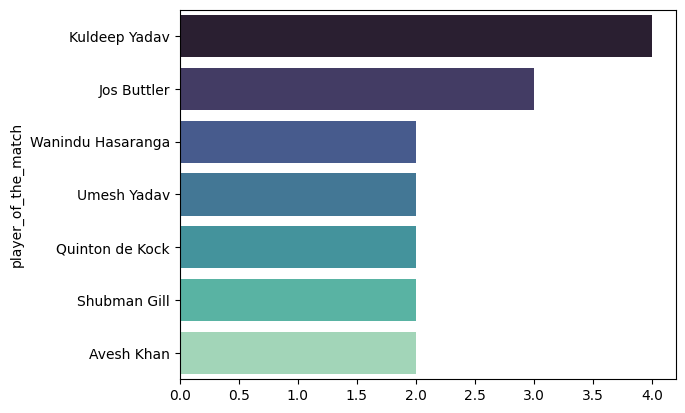

In [16]:
sns.barplot(x = pom.values, y = pom.index, palette='mako')

Top scorers

In [17]:
h_scorer = ipl_df.groupby('top_scorer')['highscore'].sum()
h_scorer = h_scorer.head(7).sort_values(ascending=False)
h_scorer

,highscore
top_scorer,
David Warner,213
Devon Conway,143
Abhishek Sharma,122
Andre Russell,119
Deepak Hooda,114
David Miller,94
Aiden Markram,57


<Axes: ylabel='top_scorer'>

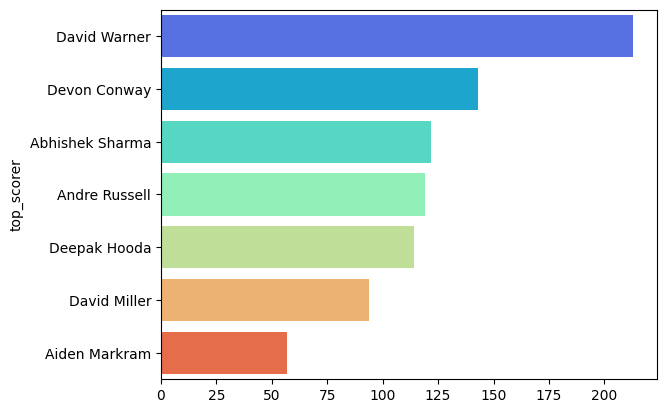

In [18]:
sns.barplot(x = h_scorer.values, y = h_scorer.index, palette="rainbow")

TOP Bowler

In [19]:
ipl_df['higest_wikets'] = ipl_df['best_bowling_figure'].apply(lambda x : x.split('--')[0])
ipl_df['higest_wikets'] = ipl_df['higest_wikets'].astype(int)
# a new column is added named higest_wikets

In [20]:
best_bowlers = ipl_df.groupby('best_bowling')['higest_wikets'].sum()
best_bowlers = best_bowlers.head(7).sort_values(ascending=False)
best_bowlers

,higest_wikets
best_bowling,
Avesh Khan,10
Andre Russell,7
Daniel Sams,7
Dwayne Bravo,6
Hardik Pandya,4
Axar Patel,2
Chetan Sakariya,2


<Axes: ylabel='best_bowling'>

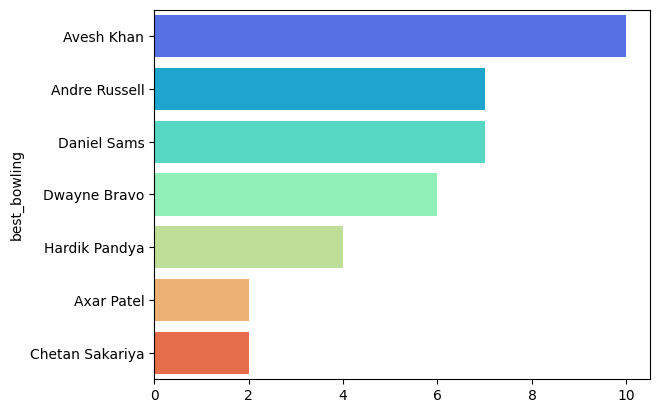

In [21]:
sns.barplot(x = best_bowlers.values, y= best_bowlers.index, palette='rainbow')

### Venue Analysis

Most Matches Played by Venue

In [28]:
count_venue = ipl_df['venue'].value_counts()
count_venue

,count
venue,
"Wankhede Stadium, Mumbai",21
"Dr DY Patil Sports Academy, Mumbai",20
"Brabourne Stadium, Mumbai",16
"Maharashtra Cricket Association Stadium,Pune",13
"Eden Gardens, Kolkata",2
"Narendra Modi Stadium, Ahmedabad",2


<Axes: xlabel='count', ylabel='venue'>

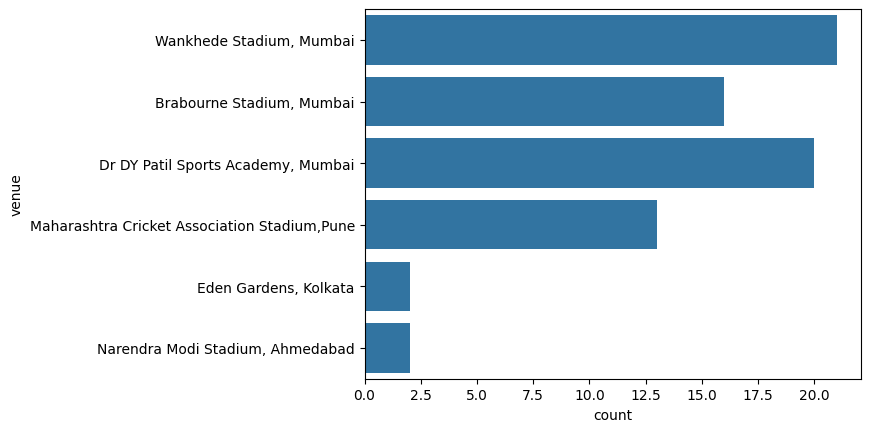

In [24]:
sns.countplot(y= ipl_df['venue'])

### Custom Questions & Insights

Q1: Who won the highest margin by runs?

In [34]:
highest_margin = ipl_df[ipl_df['won_by'] == 'Runs'].sort_values(by = 'margin', ascending= False).head(1)
highest_margin[['match_winner', 'margin']]

,match_winner,margin
54,Chennai,91


Q2: Which player had the highest individual score?

In [40]:
ipl_df.head()
HIS = ipl_df[ipl_df['highscore'] == ipl_df['highscore'].max()]
HIS[['top_scorer','highscore']]
ipl_df.head()

,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,...,second_ings_wkts,match_winner,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure,higest_wikets
0,1,"March 26,2022","Wankhede Stadium, Mumbai",Chennai,Kolkata,Group,Kolkata,Field,131,5,...,4,Kolkata,Wickets,6,Umesh Yadav,MS Dhoni,50,Dwayne Bravo,3--20,3
1,2,"March 27,2022","Brabourne Stadium, Mumbai",Delhi,Mumbai,Group,Delhi,Field,177,5,...,6,Delhi,Wickets,4,Kuldeep Yadav,Ishan Kishan,81,Kuldeep Yadav,3--18,3
2,3,"March 27,2022","Dr DY Patil Sports Academy, Mumbai",Banglore,Punjab,Group,Punjab,Field,205,2,...,5,Punjab,Wickets,5,Odean Smith,Faf du Plessis,88,Mohammed Siraj,2--59,2
3,4,"March 28,2022","Wankhede Stadium, Mumbai",Gujarat,Lucknow,Group,Gujarat,Field,158,6,...,5,Gujarat,Wickets,5,Mohammed Shami,Deepak Hooda,55,Mohammed Shami,3--25,3
4,5,"March 29,2022","Maharashtra Cricket Association Stadium,Pune",Hyderabad,Rajasthan,Group,Hyderabad,Field,210,6,...,7,Rajasthan,Runs,61,Sanju Samson,Aiden Markram,57,Yuzvendra Chahal,3--22,3


Q3: Which bowler had the best bowling figures?

In [42]:
ipl_df[ipl_df['higest_wikets'] == ipl_df['higest_wikets'].max()][['best_bowling','best_bowling_figure']]

,best_bowling,best_bowling_figure
29,Yuzvendra Chahal,5--40
39,Umran Malik,5--25
53,Wanindu Hasaranga,5--18
55,Jasprit Bumrah,5--10
